# 01 — Question, data preparation and EDA
**Group 11: Matías Muñoz Hoffmann and Clemente Ibarra**

Proposed user: a simulated LFB operations planning analyst. Initial decision: identify areas and dispatch hours that merit investigation. The later classification question asks whether information available at dispatch can flag an arrival taking at least 600 seconds. A row is **one vehicle mobilisation**, and several rows may belong to one incident.

W1 considered geographic duration differences and mobilisation volume over time. We retained arrival times, narrowed C1 to 2023–2024 and used median/P90 descriptively. After C1 feedback, W2 introduced a fixed ten-minute indicator. This is the project's analytical definition, not an official LFB service target.


# Reading this assessed notebook
This repository intentionally contains **no dataset files**. Read the saved tables, plots, explanations and code below. No execution, installation or download is required for assessment.

These cells were executed against the team's archived local inputs. `C3_PRIVATE_INPUT_ROOT` identifies that private workspace during execution; the input files are deliberately excluded from the submission. The code records how results were obtained, rather than asking the reviewer to reproduce them. No complete dataset or row-level extract appears in the saved outputs.


In [1]:
from pathlib import Path
import os,sys,json,hashlib
import numpy as np
import pandas as pd
from IPython.display import display
ROOT=Path.cwd().parent
sys.path.insert(0,str(ROOT))
PRIVATE=Path(os.environ['C3_PRIVATE_INPUT_ROOT'])
pd.set_option('display.max_rows',30)
pd.set_option('display.max_columns',14)
FIG=ROOT/'figures'


## 1. Sources, versions and observation units
The numerical mobilisation source was retrieved on 23 September 2026. The later incident/location extension is a separate source, linked many-to-one by incident number. Its publication timing and geographic fields require as-of verification before prospective use. The coordinates are approximate; the postcode station points are not vehicle GPS or road distances.


### Mobilisation source identity
Source: [official LFB mobilisation catalogue](https://data.london.gov.uk/dataset/london-fire-brigade-mobilisation-records-24r65), file **LFB Mobilisation data from 2021–2024**, retrieved **23 September 2026**. Original uncompressed CSV size: 168,034,240 bytes. Original SHA-256: `f18f9ea1943ce54ac58e3429ed2d242f9d1fa714d3a556d43d44b8a4fcf9afba`.

The local cleaned snapshot is a 2023–2024 analytical derivative; its separate hash is printed below. Published incident labels and timestamps describe this archived release, not guaranteed real-time operational values. The reviewer need not download either source.


In [2]:
manifest=json.loads((PRIVATE/'C2_Model_Improvement_20261122/data/source_manifest.json').read_text())
display(pd.DataFrame([{'source':k,'publisher':v['publisher'],'retrieved_utc':v['retrieved_utc'],'sha256':v['sha256'],'url':v['url']} for k,v in manifest.items()]))
source=PRIVATE/'C2_Model_Improvement_20261122/data/mobilisations_2023_2024_clean.csv.gz'
case=pd.read_csv(source)
print('Archived cleaned snapshot SHA-256:',hashlib.sha256(source.read_bytes()).hexdigest())
print('Eligible mobilisations:',len(case),'Distinct incidents:',case.IncidentNumber.nunique())


,source,publisher,retrieved_utc,sha256,url
0,mobilisations_2021_2024.csv,London Fire Brigade / London Datastore,2026-09-23T02:52:18.339147+00:00,f18f9ea1943ce54ac58e3429ed2d242f9d1fa714d3a556...,https://data.london.gov.uk/download/24r65/3ff2...
1,mobilisations_metadata.xlsx,London Fire Brigade / London Datastore,2026-09-23T02:52:19.851144+00:00,dec9ca5bf2feb358b6da5dc32af55610c12b7a8f55a0e8...,https://data.london.gov.uk/download/24r65/0eaa...


Archived cleaned snapshot SHA-256: c2c6569a816646dda581ebbcc24c69026caeb2b31ea47fa7a745ecfe452af481
Eligible mobilisations: 384627 Distinct incidents: 248225


## 2. Preparation choices and record flow
Historical preparation normalized text/date/number formats, removed **exact copies**, restricted dispatch dates to 2023–2024, and set aside the 16 conflicting-ID period rows. Choosing one of their geographic versions would have been arbitrary. Valid zero times and missing duration components remain when total duration agrees with timestamps. Missing geography stays Unknown in global denominators.

The recorded historical audit below documents the effect. Later feature generation does not remove difficult or unmatched mobilisations. Full model-preparation methods are retained in `src/method_record/`; the executed checks below independently test the cleaned result.


In [3]:
audit=json.loads((PRIVATE/'.project_review_20261122/sources/C1/C1_Business_Inteliggence/data/case_tables/audit.json').read_text())
flow=pd.DataFrame([['Original source, 2021–2024',audit['raw_rows']],['After 3,922 exact duplicates removed',audit['raw_rows']-audit['exact_duplicates_removed']],['2023–2024 dispatches',audit['period_rows_after_exact_dedup']],['Conflicting-ID period rows excluded',audit['excluded_kpi_rows']],['Eligible analytical rows',audit['eligible_kpi_rows']]],columns=['Preparation stage','Rows'])
display(flow)
stamp=pd.to_datetime(case.DateAndTimeMobilised,utc=True)
arrival=pd.to_datetime(case.DateAndTimeArrived,utc=True)
checks=pd.DataFrame([
 ['Missing or duplicated mobilisation IDs',int(case.ResourceMobilisationId.isna().sum()+case.ResourceMobilisationId.duplicated().sum()),'Must be zero'],
 ['Negative total duration',int(case.AttendanceTimeSeconds.lt(0).sum()),'Must be zero'],
 ['Duration disagrees with arrival minus dispatch by >1 second',int(((arrival-stamp).dt.total_seconds()-case.AttendanceTimeSeconds).abs().gt(1).sum()),'Must be zero'],
 ['Missing borough',int(case.BoroughName.isna().sum()),'Retain as Unknown'],
 ['Missing turnout or travel component',int(case[['TurnoutTimeSeconds','TravelTimeSeconds']].isna().any(axis=1).sum()),'Retain valid total'],
 ['Zero total duration',int(case.AttendanceTimeSeconds.eq(0).sum()),'Retain timestamp-consistent boundary'],
 ['Observed total above 20 minutes',int(case.AttendanceTimeSeconds.gt(1200).sum()),'Coverage limitation, not evidence of no longer responses']
 ],columns=['Check','Affected rows','Treatment'])
display(checks)
assert len(case)==384627 and case.ResourceMobilisationId.is_unique


,Preparation stage,Rows
0,"Original source, 2021–2024",727857
1,"After 3,922 exact duplicates removed",723935
2,2023–2024 dispatches,384643
3,Conflicting-ID period rows excluded,16
4,Eligible analytical rows,384627


,Check,Affected rows,Treatment
0,Missing or duplicated mobilisation IDs,0,Must be zero
1,Negative total duration,0,Must be zero
2,Duration disagrees with arrival minus dispatch...,0,Must be zero
3,Missing borough,1288,Retain as Unknown
4,Missing turnout or travel component,1816,Retain valid total
5,Zero total duration,1,Retain timestamp-consistent boundary
6,Observed total above 20 minutes,0,"Coverage limitation, not evidence of no longer..."


### Key variables and timing
`AttendanceTimeSeconds` is the outcome, not an input for the current mobilisation. Realised turnout, travel, arrival and delay codes are excluded from current-row predictors. Identifiers support audit/grouping rather than a meaningful feature. Earlier response history is eligible only after the earlier arrival has occurred, assuming immediate feedback.


In [4]:
display(pd.DataFrame([
 ['ResourceMobilisationId','identifier','one mobilisation','Required and unique after exclusions'],
 ['IncidentNumber','identifier','links vehicles at one incident','Required for overlap checks'],
 ['DateAndTimeMobilised','timestamp','GMT / UTC dispatch time','Required; prediction time'],
 ['AttendanceTimeSeconds','numeric outcome','seconds from mobilisation to arrival','Required; long if >=600'],
 ['DeployedFromStation_Code','category','published origin assignment','Dispatch-time published-field availability conditional'],
 ['DeployedFromLocation','category','Home Station / Other Station / Unknown','Physical station proxy used only for Home Station'],
 ['BoroughName / WardName','category','published incident geography','Missing kept as Unknown'],
 ['Resource_Code','category','published resource code','Assignment availability conditional'],
 ['Easting_rounded / Northing_rounded','location','metres, rounded to 50m','External matched incidents, missing retained'],
 ['Station postcode point','location proxy','metres in national grid','103 extracted points; 2025 addresses not individually verified for 2023'],
 ['Earlier-arrival aggregates','numeric history','counts, minutes and shares','Strictly earlier arrivals only']
 ],columns=['Variable','Type','Meaning / unit','Missingness or availability']))


,Variable,Type,Meaning / unit,Missingness or availability
0,ResourceMobilisationId,identifier,one mobilisation,Required and unique after exclusions
1,IncidentNumber,identifier,links vehicles at one incident,Required for overlap checks
2,DateAndTimeMobilised,timestamp,GMT / UTC dispatch time,Required; prediction time
3,AttendanceTimeSeconds,numeric outcome,seconds from mobilisation to arrival,Required; long if >=600
4,DeployedFromStation_Code,category,published origin assignment,Dispatch-time published-field availability con...
5,DeployedFromLocation,category,Home Station / Other Station / Unknown,Physical station proxy used only for Home Station
6,BoroughName / WardName,category,published incident geography,Missing kept as Unknown
7,Resource_Code,category,published resource code,Assignment availability conditional
8,Easting_rounded / Northing_rounded,location,"metres, rounded to 50m","External matched incidents, missing retained"
9,Station postcode point,location proxy,metres in national grid,103 extracted points; 2025 addresses not indiv...


## 3. EDA: distributions, geography and hour
Read the full population definition with each chart. The full eligible file contains 26,367 long mobilisations (6.855%); test prevalence is different and uses a different denominator. These geographic/hour comparisons are unadjusted associations, not estimates of crew quality or causal effects.


,Rows,Long cases,Long share %,Median minutes,P90 minutes
0,384627,26367,6.8552,5.65,9.2


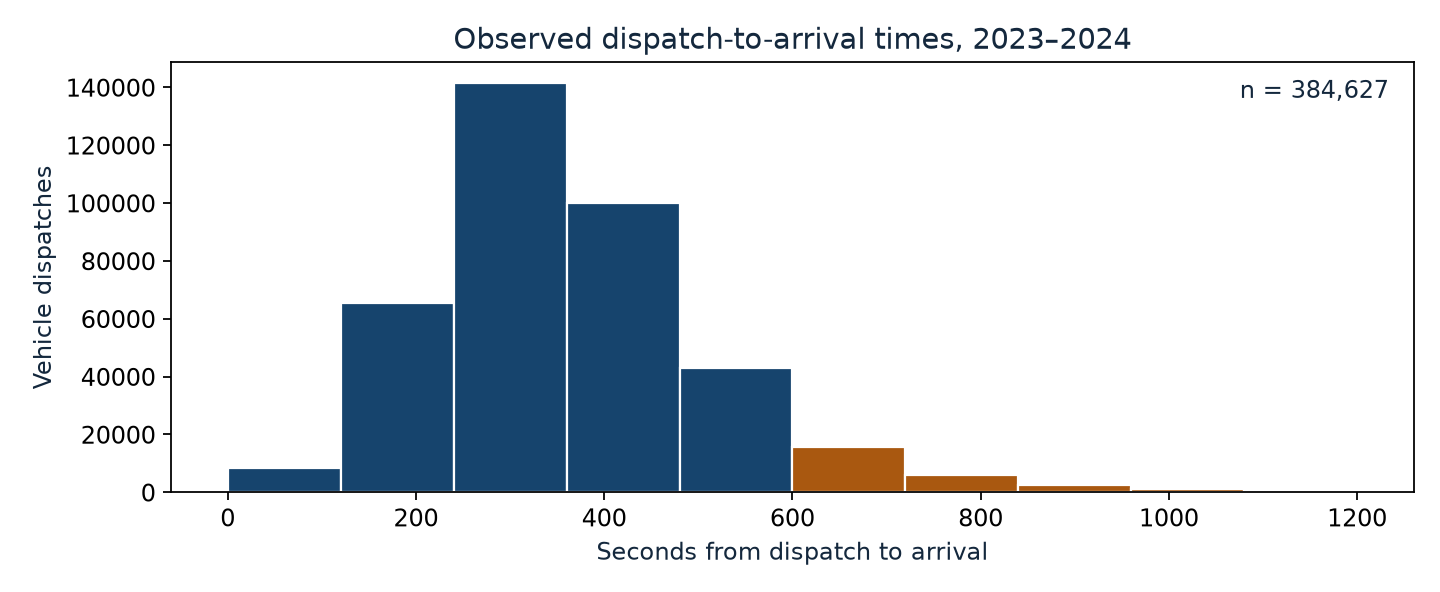

In [5]:
from src.visual_system import distribution,comparison
long=case.AttendanceTimeSeconds.ge(600)
summary=pd.DataFrame({'Rows':[len(case)],'Long cases':[int(long.sum())],'Long share %':[100*long.mean()],
                      'Median minutes':[case.AttendanceTimeSeconds.median()/60],'P90 minutes':[case.AttendanceTimeSeconds.quantile(.9)/60]})
display(summary.round(4))
display(distribution(case.AttendanceTimeSeconds.to_numpy(),FIG))


,dispatches,long_cases,long_share
published_borough,,,
HILLINGDON,12195,1578,0.129397
LAMBETH,17210,537,0.031203


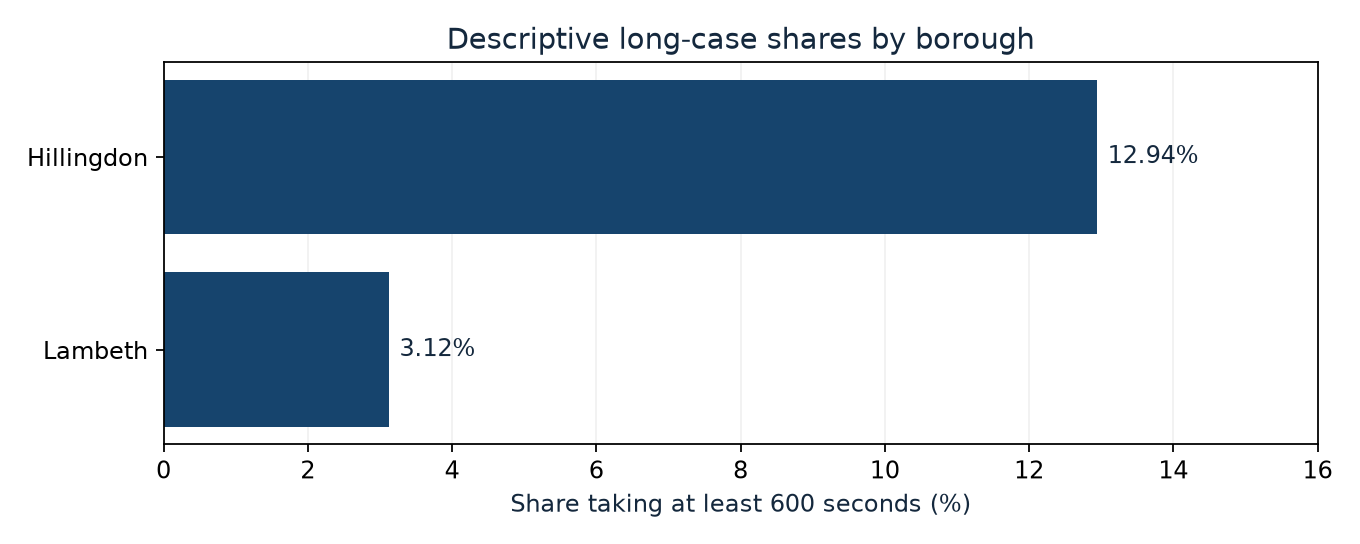

,dispatches,long_cases,long_share
DateAndTimeMobilised,,,
11,19425,1967,0.101261
4,6810,339,0.049780


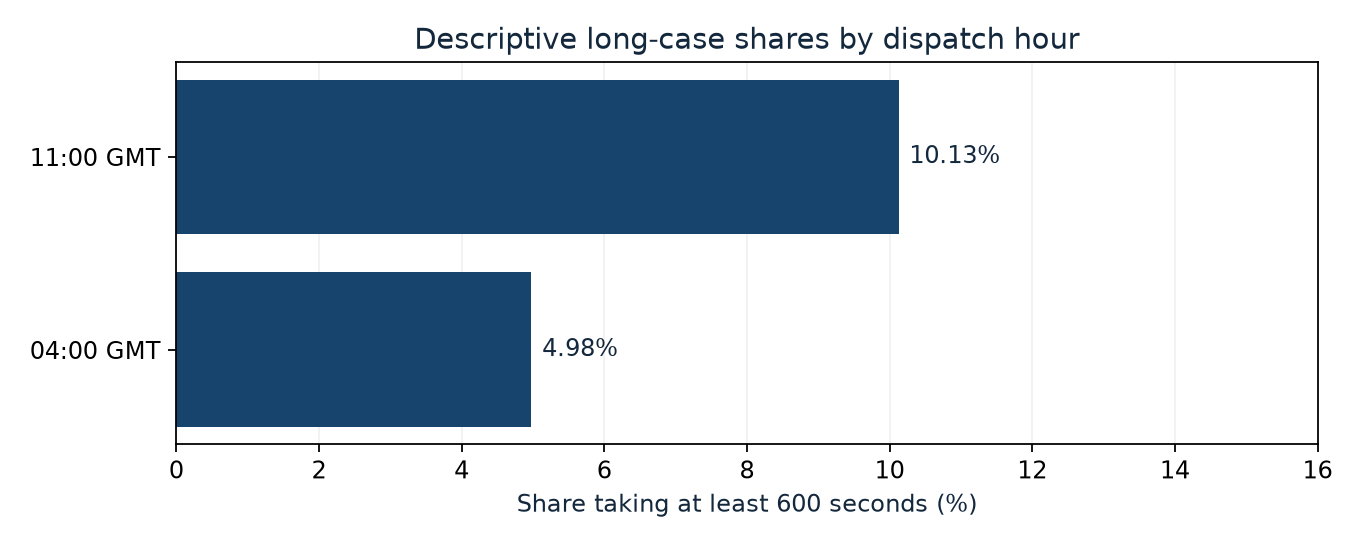

In [6]:
case['long']=long
case['published_borough']=case.BoroughName.fillna('Unknown')
borough=case.groupby('published_borough').long.agg(['size','sum','mean'])
selected=borough.loc[['HILLINGDON','LAMBETH']]
display(selected.rename(columns={'size':'dispatches','sum':'long_cases','mean':'long_share'}))
display(comparison(['Hillingdon','Lambeth'],selected['mean'].to_numpy()*100,'Descriptive long-case shares by borough','02_borough',FIG))
hour=case.groupby(stamp.dt.hour).long.agg(['size','sum','mean']).loc[[11,4]]
display(hour.rename(columns={'size':'dispatches','sum':'long_cases','mean':'long_share'}))
display(comparison(['11:00 GMT','04:00 GMT'],hour['mean'].to_numpy()*100,'Descriptive long-case shares by dispatch hour','03_hour',FIG))


## 4. Sampling and coverage
The archived W2 sample used `default_rng(423)` to select 96,157 of 384,627 eligible rows without replacement. It checks stability within the available file, not representation of every LFB incident. Neither sampling nor chronological splitting repairs the absent 31 December 2024, the unobserved tail above twenty minutes, or published inclusion rules.


In [7]:
display(pd.read_csv(PRIVATE/'.project_review_20261122/sources/W2/GROUP_11_W2/outputs/w2/sample_comparison.csv',index_col=0).round(4))
display(pd.read_csv(PRIVATE/'.project_review_20261122/sources/W2/GROUP_11_W2/outputs/w2/split_summary.csv'))
print('The complete date interval ends at:',stamp.max())


,n,at_least_10m_pct,hillingdon_share_pct,unknown_share_pct,KPI difference vs full (pp)
Full observed case,384627.0,6.8552,3.1706,0.3349,0.0000
25% random sample,96157.0,6.9095,3.2260,0.3411,0.0543


,split,n,share_pct,date_min,date_max
0,train,186339,48.446677,2023-01-01 00:00:27+00:00,2023-12-31 23:59:24+00:00
1,validation,96040,24.969646,2024-01-01 00:00:43+00:00,2024-06-30 23:58:07+00:00
2,test,102248,26.583677,2024-07-01 00:07:12+00:00,2024-12-30 23:59:59+00:00


The complete date interval ends at: 2024-12-30 23:59:59+00:00


## Interpretation carried into modelling
The data support a bounded retrospective study. Variation by hour and geography motivated predictor candidates; it did not establish causes or a staffing recommendation. Keeping a fixed 600-second outcome makes stages comparable. Continue with notebook 02 for the reference, models, thresholds and evaluation.
